In [60]:
!pip install pandas numpy matplotlib seaborn scikit-learn xgboost scipy

In [61]:
%pip install xgboost


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

from xgboost import XGBRegressor

In [63]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    LeaveOneGroupOut,
    GridSearchCV
)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

from xgboost import XGBRegressor

from scipy.stats import skellam

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [64]:
train = pd.read_csv("dataset/EuroTraining.csv")
test = pd.read_csv("dataset/EuroTest.csv")

In [65]:
#Check missing values and duplicates

print("Missing values in training data:")
print(train.isnull().sum())

print("\nMissing values in test data:")
print(test.isnull().sum())

print("\nDuplicate rows in training:")
print(train.duplicated().sum())

print("\nDuplicate rows in test:")
print(test.duplicated().sum())

Missing values in training data:
Goals          0
Team           0
Opponent       0
Year           0
GroupStage     0
GDP            0
MarketValue    0
FifaRank       0
UefaPoints     0
CLPlayers      0
dtype: int64

Missing values in test data:
Goals          0
Team           0
Opponent       0
Year           0
GroupStage     0
GDP            0
MarketValue    0
FifaRank       0
UefaPoints     0
CLPlayers      0
dtype: int64

Duplicate rows in training:
0

Duplicate rows in test:
0


In [66]:
#Understand the tournament years

print("Training tournament years:")
print(sorted(train["Year"].unique()))

print("\nTest tournament years:")
print(sorted(test["Year"].unique()))

Training tournament years:
[np.int64(2004), np.int64(2008), np.int64(2012), np.int64(2016), np.int64(2020)]

Test tournament years:
[np.int64(2024)]


count    390.000000
mean       1.205128
std        1.119573
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        5.000000
Name: Goals, dtype: float64


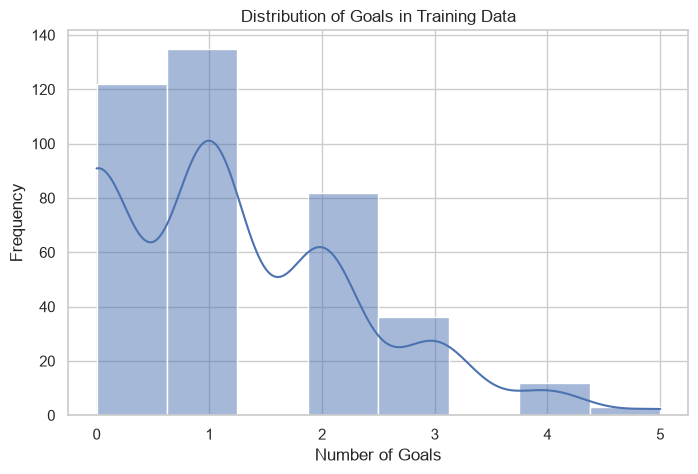

In [67]:
#Explore the response variable

print(train["Goals"].describe())

plt.figure(figsize=(8, 5))

sns.histplot(
    train["Goals"],
    bins=8,
    kde=True
)

plt.title("Distribution of Goals in Training Data")
plt.xlabel("Number of Goals")
plt.ylabel("Frequency")

plt.show()

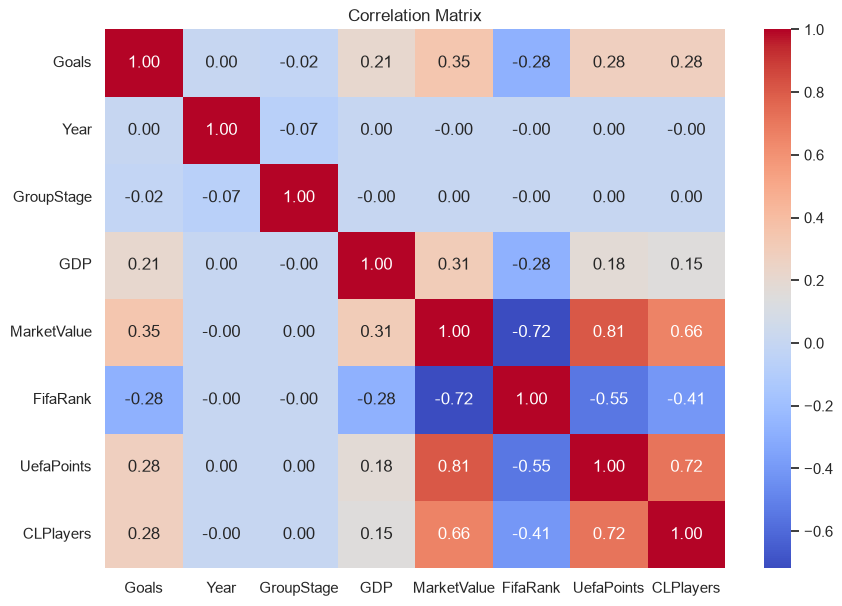

In [68]:
#relationship between the numerical predictors

plt.figure(figsize=(10, 7))

sns.heatmap(
    train.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [69]:
#Separate predictors and response variable

# Define response variable
target = "Goals"

# Define explanatory variables
features = [
    "GDP",
    "MarketValue",
    "FifaRank",
    "UefaPoints",
    "CLPlayers",
    "GroupStage"
]

# Separate X and y
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

# Tournament groups for cross-validation
groups = train["Year"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (390, 6)
y_train shape: (390,)
X_test shape: (102, 6)
y_test shape: (102,)


In [70]:
#Implement Leave-One-Group-Out Cross-Validation

from sklearn.model_selection import LeaveOneGroupOut

# Create cross-validation object
logo = LeaveOneGroupOut()

# Count folds
print("Number of folds:", logo.get_n_splits(X_train, y_train, groups))

# Display each fold
for fold, (train_idx, val_idx) in enumerate(
    logo.split(X_train, y_train, groups), start=1
):

    print(f"\nFold {fold}")

    print(
        "Training years:",
        sorted(groups.iloc[train_idx].unique())
    )

    print(
        "Validation year:",
        sorted(groups.iloc[val_idx].unique())
    )

    print("Training observations:", len(train_idx))
    print("Validation observations:", len(val_idx))

Number of folds: 5

Fold 1
Training years: [np.int64(2008), np.int64(2012), np.int64(2016), np.int64(2020)]
Validation year: [np.int64(2004)]
Training observations: 328
Validation observations: 62

Fold 2
Training years: [np.int64(2004), np.int64(2012), np.int64(2016), np.int64(2020)]
Validation year: [np.int64(2008)]
Training observations: 328
Validation observations: 62

Fold 3
Training years: [np.int64(2004), np.int64(2008), np.int64(2016), np.int64(2020)]
Validation year: [np.int64(2012)]
Training observations: 328
Validation observations: 62

Fold 4
Training years: [np.int64(2004), np.int64(2008), np.int64(2012), np.int64(2020)]
Validation year: [np.int64(2016)]
Training observations: 288
Validation observations: 102

Fold 5
Training years: [np.int64(2004), np.int64(2008), np.int64(2012), np.int64(2016)]
Validation year: [np.int64(2020)]
Training observations: 288
Validation observations: 102


In [71]:
#Check that the 2024 data is separate

print("Training years:", sorted(train["Year"].unique()))

print("Testing years:", sorted(test["Year"].unique()))

# Check overlap
overlap = set(train["Year"]).intersection(set(test["Year"]))

print("Overlapping years:", overlap)

Training years: [np.int64(2004), np.int64(2008), np.int64(2012), np.int64(2016), np.int64(2020)]
Testing years: [np.int64(2024)]
Overlapping years: set()


In [72]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define models



In [73]:
# Create an expanding-window validation strategy

years = sorted(train["Year"].unique())

rolling_folds = []

for i in range(1, len(years)):

    training_years = years[:i]
    validation_year = years[i]

    train_idx = np.where(
        train["Year"].isin(training_years)
    )[0]

    val_idx = np.where(
        train["Year"] == validation_year
    )[0]

    rolling_folds.append((train_idx, val_idx))

    print(f"\nRolling Fold {i}")

    print("Training years:", training_years)
    print("Validation year:", validation_year)

    print("Training observations:", len(train_idx))
    print("Validation observations:", len(val_idx))


Rolling Fold 1
Training years: [np.int64(2004)]
Validation year: 2008
Training observations: 62
Validation observations: 62

Rolling Fold 2
Training years: [np.int64(2004), np.int64(2008)]
Validation year: 2012
Training observations: 124
Validation observations: 62

Rolling Fold 3
Training years: [np.int64(2004), np.int64(2008), np.int64(2012)]
Validation year: 2016
Training observations: 186
Validation observations: 102

Rolling Fold 4
Training years: [np.int64(2004), np.int64(2008), np.int64(2012), np.int64(2016)]
Validation year: 2020
Training observations: 288
Validation observations: 102


In [74]:
# Convert Leave-One-Group-Out folds into a list
logo_splits = list(
    logo.split(X_train, y_train, groups)
)

print("Number of CV folds:", len(logo_splits))

Number of CV folds: 5


In [75]:
#Linear Regression

linear_model = Pipeline([
    ("model", LinearRegression())
])

In [76]:
#CART (Decision Tree)

tree_model = Pipeline([
    ("model", DecisionTreeRegressor(random_state=42))
])

tree_params = {
    "model__max_depth": [2, 3, 4, 5, None],
    "model__min_samples_leaf": [2, 5, 10],
    "model__min_samples_split": [5, 10]
}

In [77]:
#Random Forest

rf_model = Pipeline([
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [2, 5],
    "model__max_features": [0.7, 1.0]
}

In [78]:
#xg boost

xgb_model = Pipeline([
    ("model", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=42,
        n_jobs=1
    ))
])

xgb_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [1, 2, 3],
    "model__learning_rate": [0.03, 0.1],
    "model__subsample": [0.8, 1.0]
}

In [79]:
#Neural Network (MLP)

nn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPRegressor(
        random_state=42,
        max_iter=3000,
        solver="lbfgs"
    ))
])

nn_params = {
    "model__hidden_layer_sizes": [(8,), (16,), (8, 4)],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.001, 0.01, 0.1]
}

In [80]:
# Define all five machine-learning models

models = {
    "Linear Regression": (
        linear_model,
        [{}]
    ),

    "CART": (
        tree_model,
        tree_params
    ),

    "Random Forest": (
        rf_model,
        rf_params
    ),

    "Neural Network": (
        nn_model,
        nn_params
    ),

    "XGBoost": (
        xgb_model,
        xgb_params
    )
}

In [81]:
# Hyperparameter tuning using Leave-One-Group-Out CV

best_models = {}
tuning_results = []

for name, (model, params) in models.items():

    print(f"\nTraining: {name}")

    grid = GridSearchCV(
        estimator=model,
        param_grid=params,
        scoring="neg_mean_absolute_error",
        cv=logo_splits,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV MAE": -grid.best_score_,
        "Best Parameters": grid.best_params_
    })

# Create results table
tuning_df = pd.DataFrame(tuning_results)

print("\nHYPERPARAMETER TUNING RESULTS")
print(tuning_df.to_string(index=False))


Training: Linear Regression
Fitting 5 folds for each of 1 candidates, totalling 5 fits

Training: CART
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Training: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Training: Neural Network
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Training: XGBoost
Fitting 5 folds for each of 24 candidates, totalling 120 fits

HYPERPARAMETER TUNING RESULTS
            Model  Best CV MAE                                                                                               Best Parameters
Linear Regression     0.854068                                                                                                            {}
             CART     0.847123                          {'model__max_depth': 2, 'model__min_samples_leaf': 5, 'model__min_samples_split': 5}
    Random Forest     0.854790 {'model__max_depth': 3, 'model__max_features': 0.7, 'model__min_samples_leaf': 5, 'model__n_es

In [82]:
#hyperparameter tuning

logo = LeaveOneGroupOut()
logo_splits = list(
    logo.split(X_train, y_train, groups=train["Year"])
)

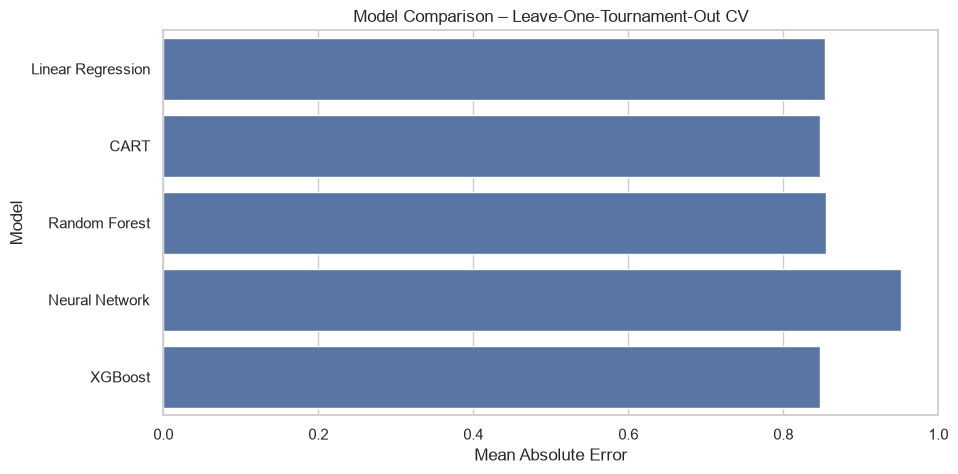

In [83]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuning_df,
    x="Best CV MAE",
    y="Model"
)

plt.title("Model Comparison – Leave-One-Tournament-Out CV")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Model")

plt.show()

      Variable  Importance       Std
1  MarketValue    0.059988  0.010863
0          GDP    0.023267  0.003065
2     FifaRank    0.019040  0.004612
4    CLPlayers    0.012364  0.003370
3   UefaPoints    0.009286  0.001532
5   GroupStage    0.001411  0.000713


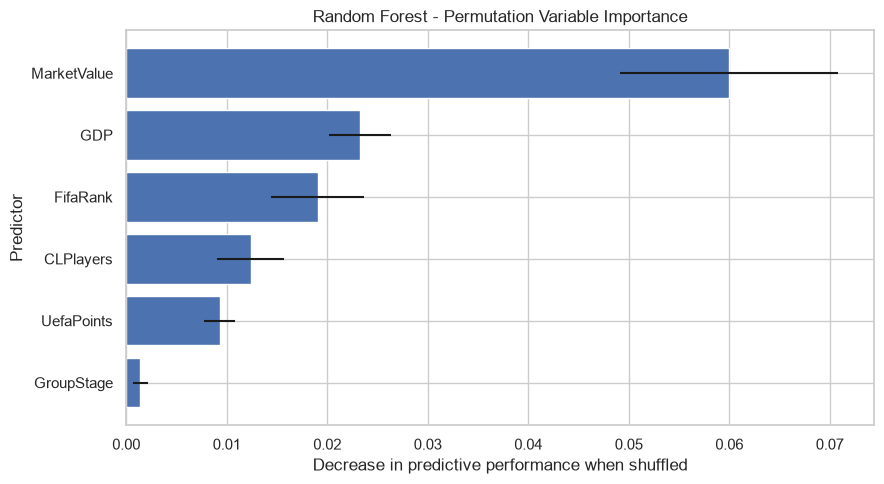

In [84]:
#Random Forest variable importance

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Use the fitted Random Forest model
rf_fitted = best_models["Random Forest"]

# Calculate permutation importance on the training data
importance = permutation_importance(
    rf_fitted,
    X_train,
    y_train,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42
)

importance_df = pd.DataFrame({
    "Variable": features,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df)

# Plot variable importance
plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Variable"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)
plt.xlabel("Decrease in predictive performance when shuffled")
plt.ylabel("Predictor")
plt.title("Random Forest - Permutation Variable Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [85]:
#Additional robustness check: Rolling-origin validation

from sklearn.metrics import mean_squared_error

In [86]:
rolling_results = []

for name, model in best_models.items():

    for fold, (train_idx, val_idx) in enumerate(
        rolling_folds, start=1
    ):

        X_tr = X_train.iloc[train_idx]
        y_tr = y_train.iloc[train_idx]

        X_val = X_train.iloc[val_idx]
        y_val = y_train.iloc[val_idx]

        # Clone model to ensure independent fitting
        from sklearn.base import clone

        model_fold = clone(model)

        model_fold.fit(X_tr, y_tr)

        predictions = model_fold.predict(X_val)

        mae = mean_absolute_error(
            y_val, predictions
        )

        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )

        rolling_results.append({
            "Model": name,
            "Fold": fold,
            "Validation Year": train["Year"].iloc[val_idx].iloc[0],
            "MAE": mae,
            "RMSE": rmse
        })

rolling_df = pd.DataFrame(rolling_results)

print(rolling_df)

                Model  Fold  Validation Year       MAE      RMSE
0   Linear Regression     1             2008  0.912835  1.116094
1   Linear Regression     2             2012  0.814506  1.026237
2   Linear Regression     3             2016  0.850448  1.030215
3   Linear Regression     4             2020  0.867195  1.092457
4                CART     1             2008  0.933149  1.118289
5                CART     2             2012  0.805846  1.008118
6                CART     3             2016  0.869532  1.034206
7                CART     4             2020  0.877917  1.098791
8       Random Forest     1             2008  0.902387  1.107026
9       Random Forest     2             2012  0.802656  1.018234
10      Random Forest     3             2016  0.858798  1.033572
11      Random Forest     4             2020  0.879467  1.102447
12     Neural Network     1             2008  1.620108  1.969826
13     Neural Network     2             2012  1.139931  1.558689
14     Neural Network    

In [87]:
rolling_summary = (
    rolling_df
    .groupby("Model")[["MAE", "RMSE"]]
    .mean()
    .sort_values("MAE")
)

print(rolling_summary)

                        MAE      RMSE
Model                                
XGBoost            0.849367  1.060127
Random Forest      0.860827  1.065320
Linear Regression  0.861246  1.066251
CART               0.871611  1.064851
Neural Network     1.240756  1.561032


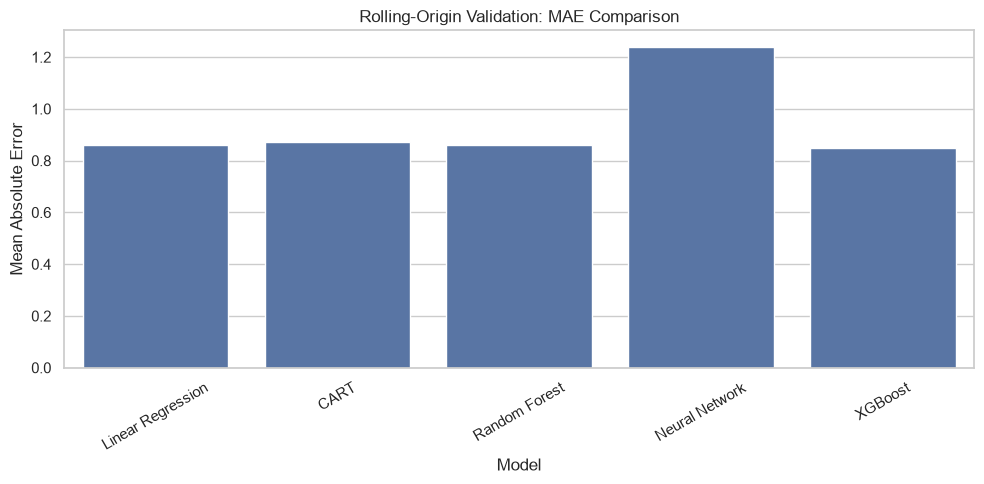

In [88]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=rolling_df,
    x="Model",
    y="MAE",
    errorbar=None
)

plt.title("Rolling-Origin Validation: MAE Comparison")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [89]:
#Predict goals for Euro 2024

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

test_results = []
test_predictions = {}

for name, model in best_models.items():

    # Predict goals for every team observation
    predictions = model.predict(X_test)

    test_predictions[name] = predictions

    # Calculate goal prediction errors
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    test_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

goal_results_df = pd.DataFrame(test_results)

goal_results_df = goal_results_df.sort_values("MAE")

print("EURO 2024 - GOAL PREDICTION RESULTS")
print(goal_results_df.to_string(index=False))

EURO 2024 - GOAL PREDICTION RESULTS
            Model      MAE     RMSE
          XGBoost 0.728911 0.965397
Linear Regression 0.740716 0.951435
    Random Forest 0.758023 0.983202
             CART 0.782869 1.008311
   Neural Network 0.870406 1.078203


In [90]:
#MAE & RMSE

goal_difference_results = []

for name, predictions in test_predictions.items():

    work = test[["Year", "Team", "Opponent", "Goals"]].copy()
    work["PredictedGoals"] = predictions

    work["MatchKey"] = work.apply(
        lambda r: (
            r["Year"],
            *sorted([str(r["Team"]), str(r["Opponent"])])
        ),
        axis=1
    )

    actual_differences = []
    predicted_differences = []

    for match_key, group in work.groupby("MatchKey", sort=False):

        if len(group) != 2:
            raise ValueError(f"Invalid match: {match_key}")

        actual_differences.append(
            group.iloc[0]["Goals"] - group.iloc[1]["Goals"]
        )

        predicted_differences.append(
            group.iloc[0]["PredictedGoals"]
            - group.iloc[1]["PredictedGoals"]
        )

    difference_mae = mean_absolute_error(
        actual_differences,
        predicted_differences
    )

    difference_rmse = np.sqrt(
        mean_squared_error(
            actual_differences,
            predicted_differences
        )
    )

    goal_difference_results.append({
        "Model": name,
        "Goal Difference MAE": difference_mae,
        "Goal Difference RMSE": difference_rmse
    })

goal_difference_df = pd.DataFrame(goal_difference_results)

print(
    goal_difference_df
    .sort_values("Goal Difference MAE")
    .to_string(index=False)
)

            Model  Goal Difference MAE  Goal Difference RMSE
          XGBoost             1.028433              1.323629
             CART             1.053941              1.385651
Linear Regression             1.060198              1.332035
   Neural Network             1.068099              1.423260
    Random Forest             1.073458              1.352435


In [91]:
#Convert predicted goals into match outcome probabilities

from scipy.stats import skellam

def evaluate_match_outcomes(df, predictions):

    work = df[["Year", "Team", "Opponent", "Goals"]].copy()
    work["PredictedGoals"] = predictions

    # Create a unique identifier for each match
    work["MatchKey"] = work.apply(
        lambda r: (
            r["Year"],
            *sorted([str(r["Team"]), str(r["Opponent"])])
        ),
        axis=1
    )

    actual_outcomes = []
    predicted_probabilities = []

    for match_key, group in work.groupby("MatchKey", sort=False):

        if len(group) != 2:
            raise ValueError(
                f"Match {match_key} does not have exactly two rows."
            )

        team1 = group.iloc[0]
        team2 = group.iloc[1]

        # Verify that both rows represent opposite perspectives
        if (team1["Team"] != team2["Opponent"] or
            team1["Opponent"] != team2["Team"]):
            raise ValueError(f"Invalid pairing: {match_key}")

        # Actual outcome:
        # 0 = loss, 1 = draw, 2 = win
        if team1["Goals"] < team2["Goals"]:
            actual = 0
        elif team1["Goals"] == team2["Goals"]:
            actual = 1
        else:
            actual = 2

        # Predicted goals must be positive for Skellam
        mu1 = max(float(team1["PredictedGoals"]), 1e-6)
        mu2 = max(float(team2["PredictedGoals"]), 1e-6)

        # Skellam probabilities
        p_loss = skellam.cdf(-1, mu1, mu2)
        p_draw = skellam.pmf(0, mu1, mu2)
        p_win = skellam.sf(0, mu1, mu2)

        actual_outcomes.append(actual)

        predicted_probabilities.append([
            p_loss,
            p_draw,
            p_win
        ])

    return (
        np.array(actual_outcomes),
        np.array(predicted_probabilities)
    )

In [92]:
#Calculate accuracy, Brier score and log-loss

from sklearn.metrics import accuracy_score, log_loss

outcome_results = []

for name, predictions in test_predictions.items():

    actual, probabilities = evaluate_match_outcomes(
        test,
        predictions
    )

    # Select the most probable outcome
    predicted_outcomes = np.argmax(probabilities, axis=1)

    # Accuracy
    accuracy = accuracy_score(
        actual,
        predicted_outcomes
    )

    # Multiclass Brier score
    actual_one_hot = np.eye(3)[actual]

    brier = np.mean(
        np.sum((probabilities - actual_one_hot) ** 2, axis=1)
    )

    # Log-loss
    logloss = log_loss(
        actual,
        probabilities,
        labels=[0, 1, 2]
    )

    outcome_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Brier Score": brier,
        "Log Loss": logloss
    })

outcome_results_df = pd.DataFrame(outcome_results)

print("EURO 2024 - MATCH OUTCOME RESULTS")

print(
    outcome_results_df
    .sort_values("Log Loss")
    .to_string(index=False)
)

EURO 2024 - MATCH OUTCOME RESULTS
            Model  Accuracy  Brier Score  Log Loss
          XGBoost  0.470588     0.596712  0.995042
    Random Forest  0.470588     0.600939  0.998105
Linear Regression  0.470588     0.610475  1.014624
             CART  0.490196     0.611452  1.015514
   Neural Network  0.470588     0.629472  1.274820


In [93]:
#RPS

rps_results = []

for name, predictions in test_predictions.items():

    actual, probabilities = evaluate_match_outcomes(
        test,
        predictions
    )

    # Current probability order: loss, draw, win
    # This is also the correct ordinal order.
    cumulative_probabilities = np.cumsum(
        probabilities[:, :2],
        axis=1
    )

    # Convert actual outcomes to cumulative indicators
    actual_cumulative = np.column_stack([
        (actual <= 0).astype(int),
        (actual <= 1).astype(int)
    ])

    # RPS for three ordered categories
    rps = np.mean(
        np.sum(
            (cumulative_probabilities - actual_cumulative) ** 2,
            axis=1
        ) / 2
    )

    rps_results.append({
        "Model": name,
        "RPS": rps
    })

rps_df = pd.DataFrame(rps_results)

print(
    rps_df.sort_values("RPS").to_string(index=False)
)

            Model      RPS
          XGBoost 0.185517
    Random Forest 0.186243
             CART 0.190700
Linear Regression 0.191294
   Neural Network 0.200105


In [94]:
# Create a combined comparison table

final_comparison = goal_results_df.merge(
    goal_difference_df,
    on="Model"
)

final_comparison = final_comparison.merge(
    outcome_results_df,
    on="Model"
)

final_comparison = final_comparison.merge(
    rps_df,
    on="Model"
)

print("FINAL EURO 2024 MODEL COMPARISON")

print(
    final_comparison
    .sort_values("MAE")
    .to_string(index=False)
)

final_comparison.to_csv(
    "Euro2024_Final_Model_Comparison.csv",
    index=False
)

print(
    "Lowest Goal Difference MAE:",
    final_comparison.loc[
        final_comparison["Goal Difference MAE"].idxmin(),
        "Model"
    ]
)

print(
    "Lowest RPS:",
    final_comparison.loc[
        final_comparison["RPS"].idxmin(),
        "Model"
    ]
)

FINAL EURO 2024 MODEL COMPARISON
            Model      MAE     RMSE  Goal Difference MAE  Goal Difference RMSE  Accuracy  Brier Score  Log Loss      RPS
          XGBoost 0.728911 0.965397             1.028433              1.323629  0.470588     0.596712  0.995042 0.185517
Linear Regression 0.740716 0.951435             1.060198              1.332035  0.470588     0.610475  1.014624 0.191294
    Random Forest 0.758023 0.983202             1.073458              1.352435  0.470588     0.600939  0.998105 0.186243
             CART 0.782869 1.008311             1.053941              1.385651  0.490196     0.611452  1.015514 0.190700
   Neural Network 0.870406 1.078203             1.068099              1.423260  0.470588     0.629472  1.274820 0.200105
Lowest Goal Difference MAE: XGBoost
Lowest RPS: XGBoost


In [95]:
#Identify the best model for each metric

print("Best model by each evaluation metric:")

print(
    "Lowest MAE:",
    final_comparison.loc[
        final_comparison["MAE"].idxmin(), "Model"
    ]
)

print(
    "Lowest RMSE:",
    final_comparison.loc[
        final_comparison["RMSE"].idxmin(), "Model"
    ]
)

print(
    "Highest Accuracy:",
    final_comparison.loc[
        final_comparison["Accuracy"].idxmax(), "Model"
    ]
)

print(
    "Lowest Brier Score:",
    final_comparison.loc[
        final_comparison["Brier Score"].idxmin(), "Model"
    ]
)

print(
    "Lowest Log Loss:",
    final_comparison.loc[
        final_comparison["Log Loss"].idxmin(), "Model"
    ]
)

Best model by each evaluation metric:
Lowest MAE: XGBoost
Lowest RMSE: Linear Regression
Highest Accuracy: CART
Lowest Brier Score: XGBoost
Lowest Log Loss: XGBoost
